# Sky + Dashboard/Hood Segmentation with FastSAM
This notebook uses `yolo_data.py` and `fastsam_detection.py` to load one image, segment sky, and optionally segment dashboard+hood from a dashcam-like viewpoint.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from yolo_data import list_images_by_split, load_image, preprocess_for_yolo
from fastsam_detection import (
    FastSAMSegmenter,
    locate_sky,
    locate_dashboard,
    draw_mask_overlay,
    draw_bbox,
 )

ROOT_DIR = Path(".")
DATASET_DIR = ROOT_DIR / "dataset/Poles2025"

In [8]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics", "-q"])
else:
    print("ultralytics is already installed")

ultralytics is already installed


In [13]:
TARGET_DATASET = "Road_poles_iPhone"
SPLIT_TO_IMAGES_DIR = {
    "train": "images/Train/train",
    "valid": "images/Validation/val",
    "test": "images/Test/test",
}

SUBSET_DIR = DATASET_DIR / TARGET_DATASET
paths_by_split = list_images_by_split(SUBSET_DIR, SPLIT_TO_IMAGES_DIR)

sample_split = "test"
sample_image = paths_by_split[sample_split][29]
print(f"Using image: {sample_image}")

image = load_image(sample_image)
print("Image shape:", image.shape)

x, meta = preprocess_for_yolo(image, image_size=640)
print("Preprocessed tensor shape:", x.shape)
print("Letterbox ratio/pad:", meta.ratio, meta.pad)

Using image: dataset/Poles2025/Road_poles_iPhone/images/Test/test/920659448.jpg
Image shape: (1920, 1080, 3)
Preprocessed tensor shape: (1, 3, 640, 640)
Letterbox ratio/pad: 0.3333333333333333 (140, 0)


In [14]:
# FastSAM model (class-agnostic segmentation)
segmenter = FastSAMSegmenter(weights="FastSAM-s.pt", conf=0.25, iou=0.9, image_size=1024)

In [15]:
sky_det = locate_sky(segmenter, sample_image)
dashboard_det = locate_dashboard(
    segmenter,
    sample_image,
    max_top_ratio=0.62,      # keep dashboard/hood in lower frame
    min_row_coverage=0.28,   # trim narrow spillover into road
 )

print("Sky segmentation:", sky_det)
print("Dashboard/Hood segmentation:", dashboard_det)

Sky segmentation: Segmentation(class_name='sky', confidence=0.38565298914909363, xyxy=(521.40673828125, 0.0, 1080.0, 1214.470947265625), mask=array([[False, False, False, ...,  True,  True, False],
       [False, False, False, ...,  True,  True, False],
       [False, False, False, ...,  True,  True, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(1920, 1080)))
Dashboard/Hood segmentation: Segmentation(class_name='dashboard', confidence=0.4447517693042755, xyxy=(0.0, 1190.0, 1079.0, 1907.0), mask=array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], s

Sky bbox (xyxy): (521.40673828125, 0.0, 1080.0, 1214.470947265625)
Dashboard/Hood bbox (xyxy): (0.0, 1190.0, 1079.0, 1907.0)


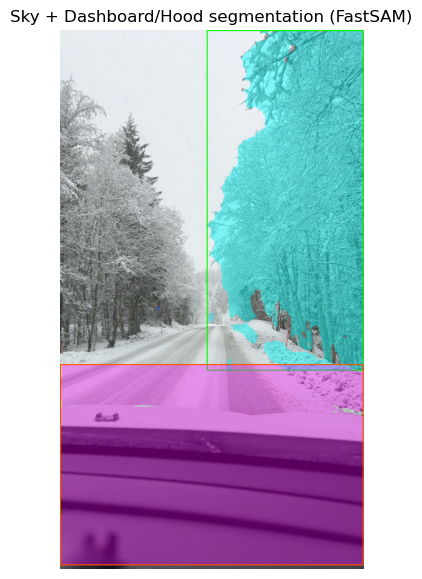

In [16]:
# Visualize result
canvas = image.copy()

if sky_det is not None:
    canvas = draw_mask_overlay(canvas, sky_det.mask, color=(0, 255, 255), alpha=0.45)
    canvas = draw_bbox(canvas, sky_det.xyxy, color=(0, 255, 0), thickness=4)
    x1, y1, x2, y2 = sky_det.xyxy
    print(f"Sky bbox (xyxy): {(x1, y1, x2, y2)}")
else:
    print("No sky segmentation found. Try a different image or lower `conf`.")

if dashboard_det is not None:
    canvas = draw_mask_overlay(canvas, dashboard_det.mask, color=(255, 0, 255), alpha=0.35)
    canvas = draw_bbox(canvas, dashboard_det.xyxy, color=(255, 80, 0), thickness=4)
    dx1, dy1, dx2, dy2 = dashboard_det.xyxy
    print(f"Dashboard/Hood bbox (xyxy): {(dx1, dy1, dx2, dy2)}")
else:
    print("No dashboard/hood segmentation found (camera may not be dashcam-facing).")

plt.figure(figsize=(12, 7))
plt.imshow(canvas)
plt.title("Sky + Dashboard/Hood segmentation (FastSAM)")
plt.axis("off")
plt.show()